# The v5 engine vs the v4 engine — the forced-win layer on a common trajectory

## Goal

Measure the deployed root — `vcf.search_v5` (connect6/vcf.py): the v4 enhanced search plus
the forced-win layer (docs/EVALUATION.md, section 11) — against the v4 engine it extends,
on the same deterministic trajectory the v4 notebook uses against v3: one v4-vs-v4
self-play, center opening, white's first reply IIKK, depth 3, 48-ply cap, every decision
point re-analyzed by both engines at the deployment depth through `harness.analyze_history`
(one worker process per position and search). The position battery (section 11.3) proves
the layer's skills end to end; this notebook prices the layer move by move and records
where it changes the engine's mind.

Weights are pinned to `tuning/winner.json`, the shipped champion. Both engines are
deterministic, so node counts, scores and moves reproduce docs/EVALUATION.md, section 11.3
exactly; wall seconds under twelve-way load are indicative only, so the record is nodes.

## Expected behaviour

The layer must (1) answer every proven-win position of the trajectory's last stretch in
exactly one node — stage 1 returns before any tree search, (2) price six verdict bands v4
leaves mid-band: five one-node stage-1 answers (prefixes 42, 44, 45, 46, 47) plus one
budgeted-deepening find (prefix 36, 70 nodes), (3) change 35 of 48 moves — deepening and
the defence screen shift quiet development choices — and (4) pay for it: 4.4x v4's mean
nodes (29,486 vs 6,667), with the screen's probe cost spiking to 233,374 nodes on the
sharpest position (prefix 34).

Runtime: about 6 minutes (the self-play regeneration dominates; the analyses run in parallel).


In [1]:
import os
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.search import search_alpha_beta_with_quiescence
from connect6.vcf import search_v5

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## The common trajectory

The recorded game is generated by the same protocol as the v4 notebook's v3-vs-v4
measurement and asserted move-for-move identical: the trajectory is shared, so v3, v4 and
v5 are all priced on one forty-eight-decision-point game.


In [2]:
EXPECTED_HISTORY = 'JJ IIKK JKLJ KJKI KLJI JLIJ JHLH JGIH KHLI LKIG IKIF LGHG KGKF KEJF HHMJ MHNK GGLF MEML NMLM MNLE JENE MKLD OKMC MMNJ MOHK LLOI KMPH NLNI NHNN GKHI GJOM OJPL OLPK ONLN PIIL FIKN GIHL GHHJ GMQJ FNRI FGHM FLKO EMJP FMGN PJLP KQPG FOIM JMHO INEL'.split()

enhanced_player = harness.search_player(search_alpha_beta_with_quiescence)
trajectory = harness.play_game(enhanced_player, enhanced_player, 3, white_first_reply="IIKK", max_plies=48)
history = ["JJ"] + trajectory.moves
assert history == EXPECTED_HISTORY
assert trajectory.winner is None and trajectory.plies == 48
print(f"trajectory: 48-ply v4 self-play, no win inside the cap")

rows = harness.analyze_history(history, [("v4", search_alpha_beta_with_quiescence), ("v5", search_v5)], 3)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v4", "v5")}
changes = sum(1 for p in positions if per_prefix[p]["v4"].move != per_prefix[p]["v5"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v4"].score) >= 20000) != (abs(per_prefix[p]["v5"].score) >= 20000))
ones = [p for p in positions if per_prefix[p]["v5"].nodes == 1]
peak = max(positions, key=lambda p: per_prefix[p]["v5"].nodes)
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v4", "v5"):
    top = max(per_prefix[p][name].nodes for p in positions)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d}")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}   v5 node peak: prefix {peak}")
print(f"one-node stage-1 answers: {ones}")
for p in ones:
    row = per_prefix[p]
    print(f"  prefix {p:2d}: v5 answers {row['v5'].move} at {row['v5'].score} in one node; "
          f"v4 scored {row['v4'].score} in {row['v4'].nodes:,} nodes")


trajectory: 48-ply v4 self-play, no win inside the cap


engine  total nodes mean/position     peak
v4          320,038         6,667   40,262
v5        1,415,330        29,486  233,374
move changes: 35/48   verdict-band flips: 6/48   v5 node peak: prefix 34
one-node stage-1 answers: [42, 44, 45, 46, 47]
  prefix 42: v5 answers IMJM at 20000 in one node; v4 scored 441 in 9,689 nodes
  prefix 44: v5 answers IMJM at 20000 in one node; v4 scored 1961 in 4,808 nodes
  prefix 45: v5 answers FKFJ at -20000 in one node; v4 scored -278 in 11,979 nodes
  prefix 46: v5 answers IMJM at 20000 in one node; v4 scored 474 in 21,722 nodes
  prefix 47: v5 answers FKFJ at -20000 in one node; v4 scored -561 in 9,514 nodes


In [3]:
EXPECTED_V5 = {"v4_nodes": 320038, "v5_nodes": 1415330, "changes": 35, "flips": 6, "ones": [42, 44, 45, 46, 47], "v5_peak": 233374}
assert totals["v4"] == EXPECTED_V5["v4_nodes"]
assert totals["v5"] == EXPECTED_V5["v5_nodes"]
assert changes == EXPECTED_V5["changes"]
assert flips == EXPECTED_V5["flips"]
assert ones == EXPECTED_V5["ones"]
assert max(per_prefix[p]["v5"].nodes for p in positions) == EXPECTED_V5["v5_peak"]
assert per_prefix[36]["v5"].score == 20000 and per_prefix[36]["v5"].nodes == 70
print("the layer's price and verdicts reproduce section 11.3 exactly (nodes, changes, flips, one-node answers)")


the layer's price and verdicts reproduce section 11.3 exactly (nodes, changes, flips, one-node answers)


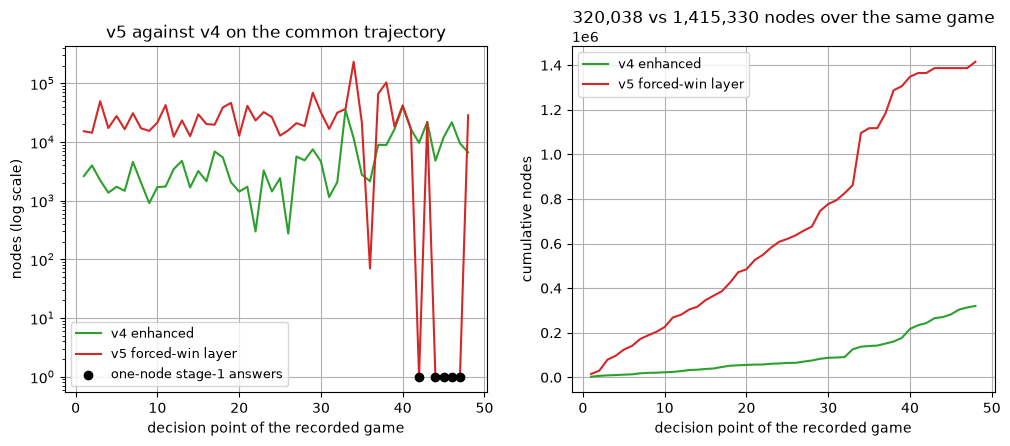

In [4]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v4"].nodes for p in positions], color="tab:green", label="v4 enhanced")
ax.plot(positions, [per_prefix[p]["v5"].nodes for p in positions], color="tab:red", label="v5 forced-win layer")
ax.scatter(ones, [1] * len(ones), color="black", zorder=3, label="one-node stage-1 answers")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v5 against v4 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v4"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:green", label="v4 enhanced")
ax2.plot(positions, [sum(per_prefix[q]["v5"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:red", label="v5 forced-win layer")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("320,038 vs 1,415,330 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## Reading the results

- **The layer sees wins the v4 engine never prices** — in the last stretch of a game the
  v4 engine played to a 48-ply standstill, five positions had proven forced wins for the
  side to move (both colors); stage 1 answers each in a single node, and budgeted
  deepening finds a sixth (prefix 36) that the depth-3 floor misses. The v4 engine sailed
  through all six.
- **The price is real and lumpy** — 4.4x v4's mean nodes over the game: quiet development
  pays the deepening budget, and the defence screen's probe cost spikes twentyfold on the
  sharpest position (233,374 nodes at prefix 34, against v4's 11,612). The one-node answers
  cost nothing at all: a proven win is cheaper than a quiet move.
- **Move changes cluster away from the verdict flips** — 35 of 48 moves differ (deepening
  looks past the depth-3 horizon and the screen vetoes handovers), yet only six verdict
  bands flip: the layer mostly buys better quiet moves, and when it buys a verdict, it is
  a proven one.
- The skills themselves — forced wins in 1-3 turns, defence, opening consistency — are the
  position battery's business (section 11.3); this notebook is the layer's price tag.
  Full discussion: docs/EVALUATION.md, sections 11.1, 11.3 and 11.4.
